In [1]:
import pandas as pd
import numpy as np
from plotnine import *
import os

In [2]:
paabd_ls = ['sh2','fha','1433','ww']
final_ls = []
for paabd in paabd_ls:
    sim_id = f'251125_pymc_{paabd}'
    effects_df = pd.read_csv('./decoupling_out/' + sim_id + '.csv').iloc[:,1:]
    stats_df = pd.read_csv(f'./decoupling_out/251125_pymc_binding_stats_{paabd}.csv').iloc[:,1:]
    effects_df['paabd'] = paabd
    final = pd.merge(effects_df,stats_df, on = ['substrate','kinase'])
    final = final.drop(['pair_total_effect'],axis = 1)
    final_ls.append(final)

In [3]:
specificity_df = pd.concat(final_ls)

In [4]:
count_df = pd.read_pickle('./decoupling_out/raw_screen_count_mapped.pkl')
count_df = count_df.drop(['barcode_seq'],axis = 1)
count_df = count_df.groupby(['kinase_name','substrate_aa','paabd']).sum().reset_index()
count_df.columns = ['kinase', 'substrate', 'paabd', 'pre_1', 'mtx_1', 'pre_2',
       'mtx_2']

In [5]:
specificity_df = pd.merge(specificity_df,count_df,on = ['substrate','kinase','paabd'])

In [6]:
specificity_df['kinase'].drop_duplicates()

0                 FES_HUMAN
1                 FRK_HUMAN
2                 FYN_HUMAN
3              JAK2_HUMAN_1
4                KSYK_HUMAN
5               STYK1_HUMAN
6                TNK1_HUMAN
26               ABL2_HUMAN
13224            IKKB_HUMAN
13225           KKCC1_HUMAN
13226    KS6B1_HUMAN_active
13227        KS6B1_HUMAN_wt
13228            M3K7_HUMAN
13229           PDPK1_HUMAN
13230           PHKG1_HUMAN
13231            PLK1_HUMAN
13232     PLK1_HUMAN_active
13233           TITIN_HUMAN
13234           ADCK1_HUMAN
13235            KGP1_HUMAN
13247           MAST1_HUMAN
13273            TBK1_HUMAN
13399            PIM1_HUMAN
Name: kinase, dtype: str

In [10]:
specificity_df.to_pickle('./251130_ksi_inference_scores.pkl')

/opt/conda/lib/python3.11/site-packages/plotnine/layer.py:293: PlotnineWarning: stat_bin : Removed 29 rows containing non-finite values.
/opt/conda/lib/python3.11/site-packages/plotnine/layer.py:374: PlotnineWarning: geom_histogram : Removed 8 rows containing missing values.
/opt/conda/lib/python3.11/site-packages/plotnine/themes/themeable.py:2486: FutureWarning: You no longer need to use subplots_adjust to make space for the legend or text around the panels. This parameter will be removed in a future version. You can still use 'plot_margin' 'panel_spacing' for your other spacing needs.


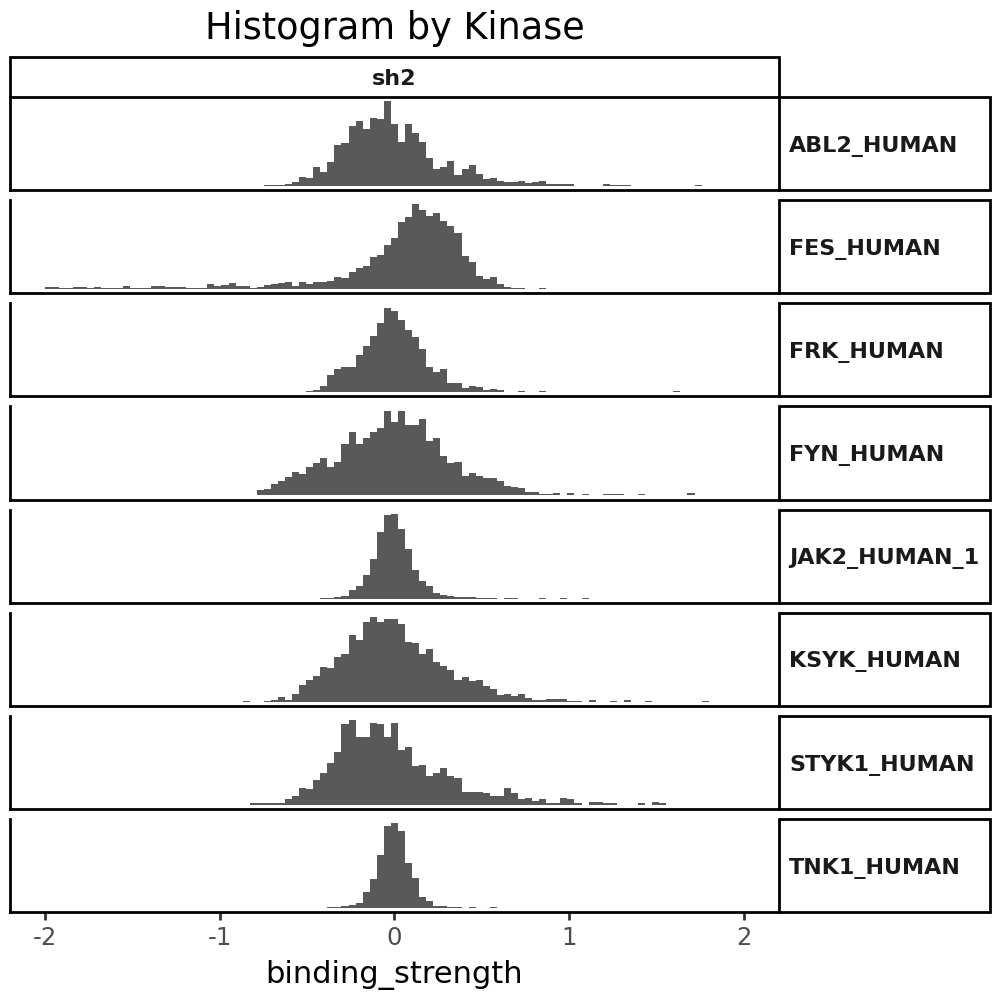

In [7]:
from plotnine import *
p = ( ggplot( specificity_df.loc[specificity_df['paabd']=='sh2',:], # keep it tidy 
              aes(x='binding_strength') ) + geom_histogram(bins=100) # adjust bins as you like 
      +xlim((-2,2))
      + facet_grid(rows = ['kinase'], cols = ['paabd'], scales='free_y') 
      + labs( title='Histogram by Kinase', x='binding_strength', y='Count' ) 
      + theme_classic() 
      + theme(subplots_adjust={'wspace': 0.25}) 
      + theme(
        strip_text_y=element_text(size=8, weight='bold', rotation=0, ha='left', va='center'),
        figure_size=(5, 5),
        strip_text_x=element_text(size=8, weight='bold'),
        axis_ticks_major_y=element_blank(),
        axis_ticks_minor_y=element_blank(),
        axis_text_y=element_blank(),
        axis_title_y=element_blank(),   # remove "Count" too; delete this line if you want to keep it
    )
    )

p              

/opt/conda/lib/python3.11/site-packages/plotnine/layer.py:293: PlotnineWarning: stat_bin : Removed 109 rows containing non-finite values.
/opt/conda/lib/python3.11/site-packages/plotnine/layer.py:374: PlotnineWarning: geom_histogram : Removed 45 rows containing missing values.
/opt/conda/lib/python3.11/site-packages/plotnine/themes/themeable.py:2486: FutureWarning: You no longer need to use subplots_adjust to make space for the legend or text around the panels. This parameter will be removed in a future version. You can still use 'plot_margin' 'panel_spacing' for your other spacing needs.


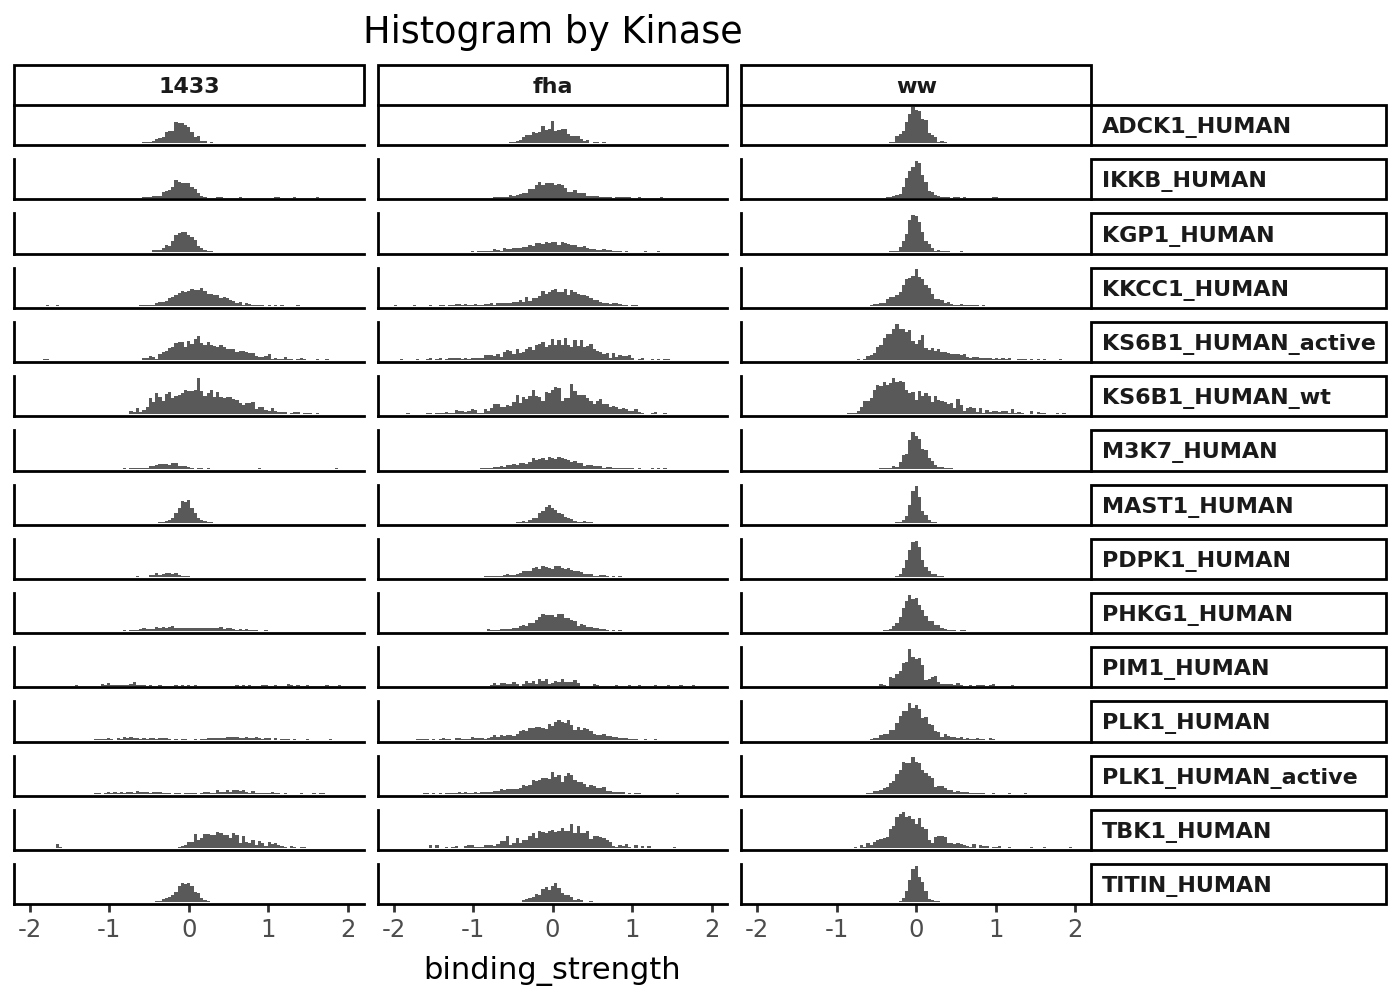

In [8]:
p = ( ggplot( specificity_df.loc[specificity_df['paabd']!='sh2',:], # keep it tidy 
              aes(x='binding_strength') ) + geom_histogram(bins=100) # adjust bins as you like 
      +xlim((-2,2))
      + facet_grid(rows = ['kinase'], cols = ['paabd'], scales='free_y') 
      + labs( title='Histogram by Kinase', x='binding_strength', y='Count' ) 
      + theme_classic() 
      + theme(subplots_adjust={'wspace': 0.25}) 
      + theme(
        strip_text_y=element_text(size=8, weight='bold', rotation=0, ha='left', va='center'),
        figure_size=(7,5),
        strip_text_x=element_text(size=8, weight='bold'),
        axis_ticks_major_y=element_blank(),
        axis_ticks_minor_y=element_blank(),
        axis_text_y=element_blank(),
        axis_title_y=element_blank(),   # remove "Count" too; delete this line if you want to keep it
    )
    )

p     

/opt/conda/lib/python3.11/site-packages/plotnine/themes/themeable.py:2486: FutureWarning: You no longer need to use subplots_adjust to make space for the legend or text around the panels. This parameter will be removed in a future version. You can still use 'plot_margin' 'panel_spacing' for your other spacing needs.


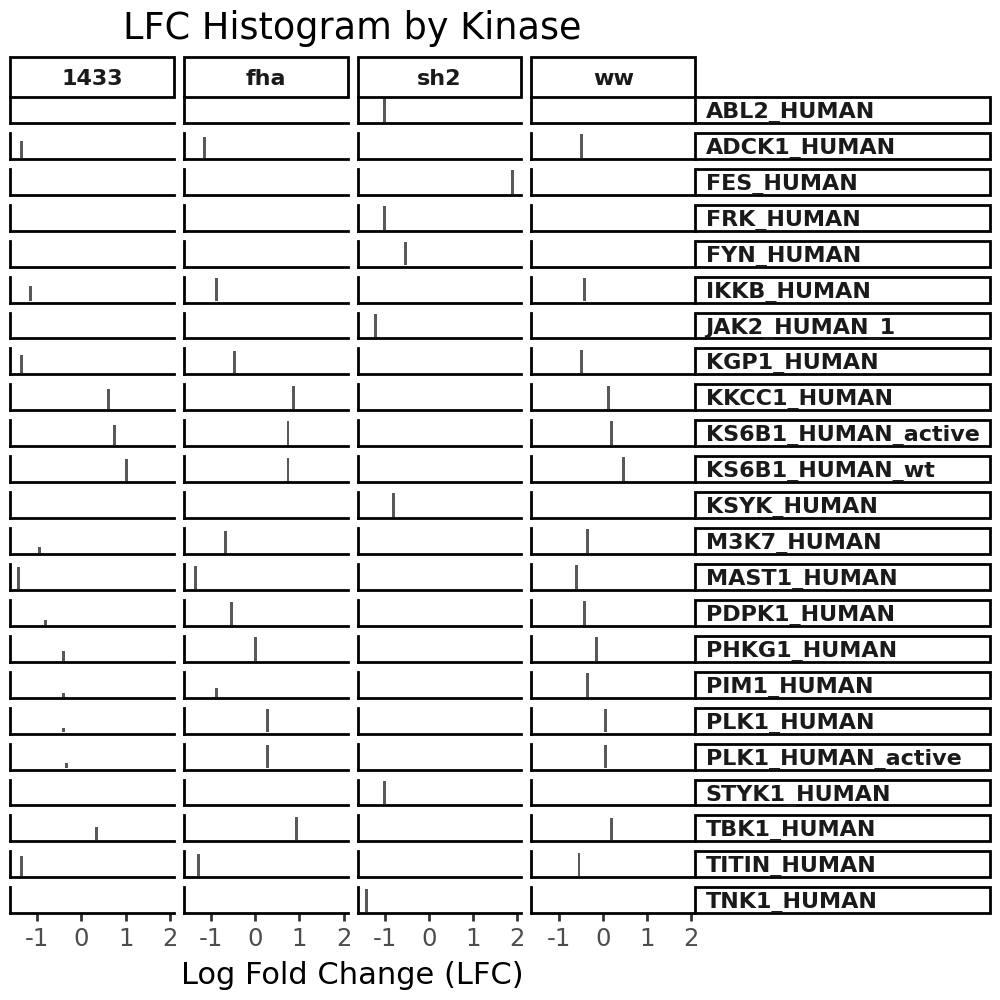

In [9]:
p = (
    ggplot(specificity_df, aes(x='kinase_global'))
    + geom_histogram(bins=50)
    + facet_grid(rows=['kinase'], cols=['paabd'], scales='free_y')
    + labs(title='LFC Histogram by Kinase', x='Log Fold Change (LFC)', y='Count')
    + theme_classic()
    + theme(subplots_adjust={'wspace': 0.25})
    + theme(
        strip_text_y=element_text(size=8, weight='bold', rotation=0, ha='left', va='center'),
        figure_size=(5, 5),
        strip_text_x=element_text(size=8, weight='bold'),
        axis_ticks_major_y=element_blank(),
        axis_ticks_minor_y=element_blank(),
        axis_text_y=element_blank(),
        axis_title_y=element_blank(),   # remove "Count" too; delete this line if you want to keep it
    )
)

p

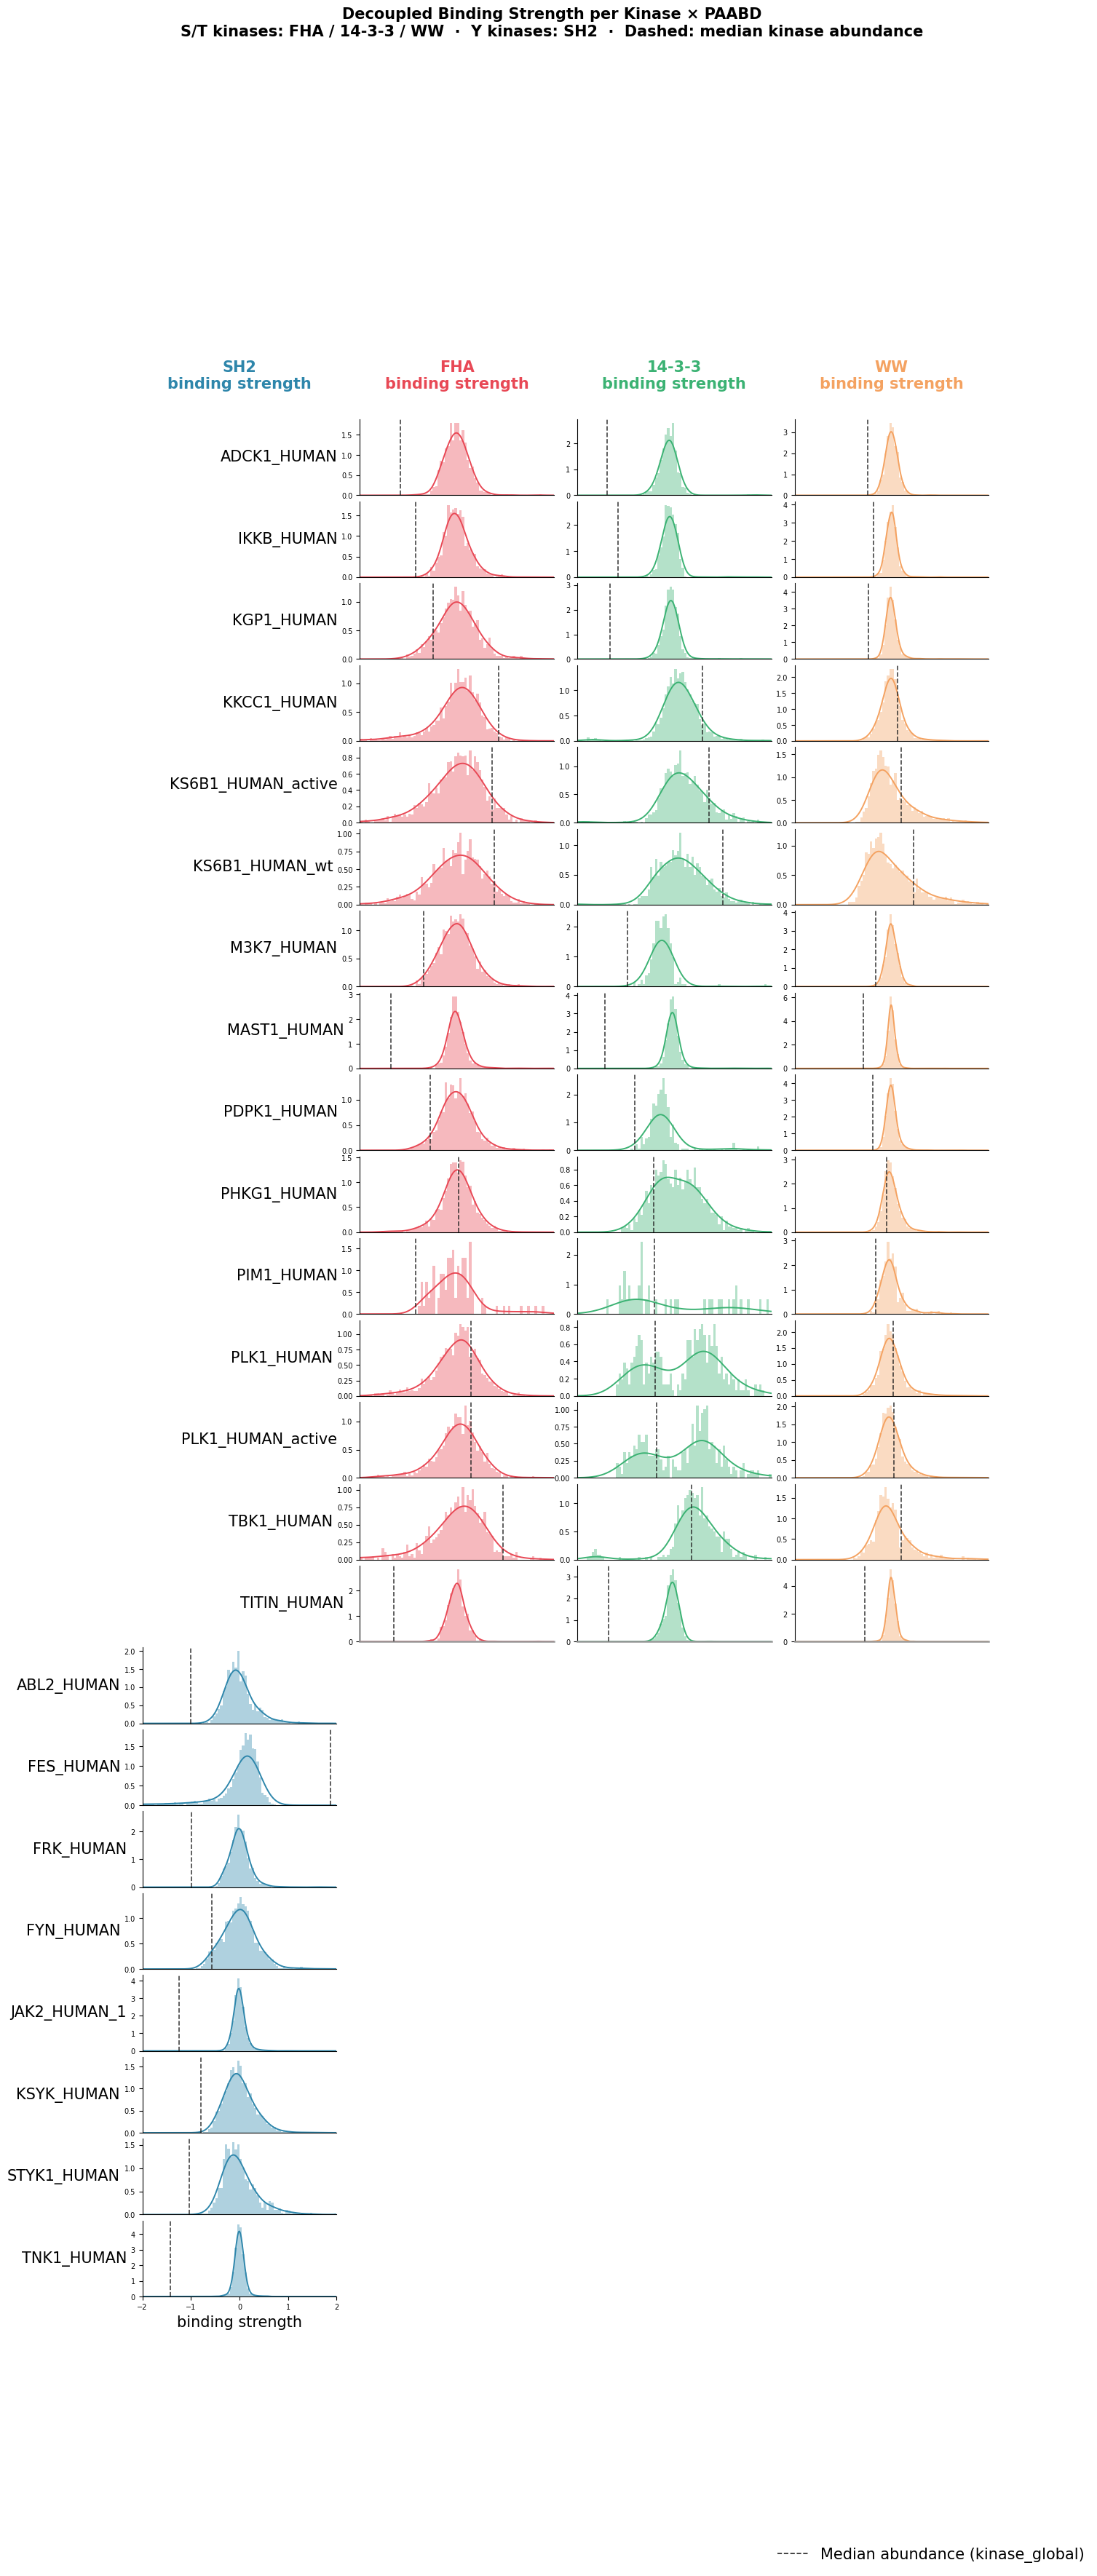

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
from scipy.stats import gaussian_kde

# ── Style ─────────────────────────────────────────────────────────────────────
plt.rcParams.update({
    'font.family':     'sans-serif',
    'font.sans-serif': ['DejaVu Sans', 'Helvetica', 'Liberation Sans'],
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'axes.labelsize':  9,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
})

PAABD_ORDER  = ['sh2', 'fha', '1433', 'ww']
PAABD_LABELS = {'sh2': 'SH2', 'fha': 'FHA', '1433': '14-3-3', 'ww': 'WW'}
PAABD_COLORS = {'sh2': '#2E86AB', 'fha': '#E84855', '1433': '#3BB273', 'ww': '#F4A261'}
ABUND_COLOR  = '#222222'

# ── Kinase → pAABD membership ─────────────────────────────────────────────────
kinase_paabds = (
    specificity_df.groupby('kinase')['paabd']
    .apply(lambda x: set(x.unique()))
    .to_dict()
)
st_kinases = sorted([k for k, ps in kinase_paabds.items() if 'fha' in ps])
y_kinases  = sorted([k for k, ps in kinase_paabds.items() if 'sh2' in ps])
all_kinases = st_kinases + y_kinases

# ── Safe KDE helper ───────────────────────────────────────────────────────────
def safe_kde(vals, xrange=(-2, 2), bw=0.4, n=400):
    vals = np.asarray(pd.Series(vals).dropna())
    if len(vals) < 3 or np.unique(vals).size < 3:
        return None, None
    try:
        xg = np.linspace(*xrange, n)
        return xg, gaussian_kde(vals, bw_method=bw)(xg)
    except np.linalg.LinAlgError:
        return None, None

def blank_ax(ax):
    ax.set_visible(False)

# ═══════════════════════════════════════════════════════════════════════════════
# FIGURE 1  —  Activity histogram + single vertical line for median abundance
# Rows = kinases (S/T block then Y block)
# Cols = [SH2 | FHA | 14-3-3 | WW]
# Blank cell if kinase not screened in that pAABD
# Vertical line = median kinase_global for that kinase × pAABD
# ═══════════════════════════════════════════════════════════════════════════════
n_all = len(all_kinases)

fig1, axes1 = plt.subplots(
    n_all + 1, len(PAABD_ORDER),
    figsize=(15, 1.45 * n_all + 1.6),
    gridspec_kw=dict(hspace=0.08, wspace=0.12),
)

# ── Column headers ────────────────────────────────────────────────────────────
for ci, paabd in enumerate(PAABD_ORDER):
    ax_h = axes1[0, ci]
    ax_h.text(0.5, 0.5,
              f'{PAABD_LABELS[paabd]}\nbinding strength',
              ha='center', va='center', fontsize=15,
              fontweight='bold', color=PAABD_COLORS[paabd])
    ax_h.axis('off')

# ── Per-kinase rows ───────────────────────────────────────────────────────────
for row_idx, kinase in enumerate(all_kinases):
    df_k    = specificity_df.loc[specificity_df['kinase'] == kinase]
    is_last = (row_idx == n_all - 1)

    for ci, paabd in enumerate(PAABD_ORDER):
        ax = axes1[row_idx + 1, ci]

        # blank if kinase not screened in this pAABD
        if paabd not in kinase_paabds.get(kinase, set()):
            blank_ax(ax)
            continue

        df_pk  = df_k.loc[df_k['paabd'] == paabd, 'binding_strength'].dropna()
        ab_pk  = df_k.loc[df_k['paabd'] == paabd, 'kinase_global'].dropna()
        color  = PAABD_COLORS[paabd]
        xrange = (-2, 2)

        # histogram
        if len(df_pk):
            ax.hist(df_pk, bins=80, range=xrange,
                    color=color, alpha=0.38, density=True, linewidth=0)

        # KDE
        xg, yg = safe_kde(df_pk, xrange=xrange)
        if xg is not None:
            ax.plot(xg, yg, color=color, linewidth=1.4)

        # single vertical line = median abundance for this kinase × pAABD
        if len(ab_pk):
            med_abund = ab_pk.median()
            ax.axvline(med_abund, color=ABUND_COLOR, linewidth=1.2,
                       linestyle='--', alpha=0.85, zorder=5)

        ax.set_xlim(*xrange)
        ax.set_ylim(bottom=0)
        # ax.set_yticks([])
        # ax.spines['left'].set_visible(False)

        # kinase label on leftmost visible column
        if ci == 0 or all(
            p not in kinase_paabds.get(kinase, set())
            for p in PAABD_ORDER[:ci]
        ):
            ax.set_ylabel(kinase, fontsize=15, rotation=0,
                          ha='right', va='center', labelpad=4)

        if is_last:
            ax.set_xlabel('binding strength', fontsize=15)
            ax.xaxis.set_major_locator(plt.MultipleLocator(1))
        else:
            ax.set_xticks([])

    # divider between S/T and Y blocks
    if row_idx == len(st_kinases) - 1:
        for ci in range(len(PAABD_ORDER)):
            ax = axes1[row_idx + 1, ci]
            if ax.get_visible():
                ax.spines['bottom'].set_linewidth(1.8)
                ax.spines['bottom'].set_color('#999999')

# shared legend
legend_handles = [
    Line2D([0], [0], color=ABUND_COLOR, linewidth=1.2, linestyle='--',
           label='Median abundance (kinase_global)'),
]
fig1.legend(handles=legend_handles, loc='lower right',
            fontsize=15, frameon=False, bbox_to_anchor=(1.0, 0.0))

fig1.suptitle(
    'Decoupled Binding Strength per Kinase × PAABD\n'
    'S/T kinases: FHA / 14-3-3 / WW  ·  Y kinases: SH2  ·  '
    'Dashed: median kinase abundance',
    fontsize=15, fontweight='bold', y=1.01,
)
fig1.savefig('./supp_plot_outputs/fig1_activity_abundance.pdf',
             dpi=300, bbox_inches='tight', format='pdf')
plt.show()



In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# FIGURE 2  —  Cross-PAABD abundance heatmap (S/T kinases, FHA/14-3-3/WW only)
# Uses fitted kinase_global median directly — no z-scoring, no normalization
# Two panels: raw median LFC | z-score within each pAABD column
# ═══════════════════════════════════════════════════════════════════════════════
ST_HEATMAP_PAABDS = ['fha', '1433', 'ww']

abund_records = []
for kinase in st_kinases:
    df_k = specificity_df.loc[specificity_df['kinase'] == kinase]
    for paabd in ST_HEATMAP_PAABDS:
        df_pk = df_k.loc[df_k['paabd'] == paabd, 'kinase_global'].dropna()
        abund_records.append({
            'kinase': kinase,
            'paabd':  paabd,
            'median': df_pk.median() if len(df_pk) > 0 else np.nan,
        })

abund_df = pd.DataFrame(abund_records)
pivot    = abund_df.pivot(index='kinase', columns='paabd',
                          values='median')[ST_HEATMAP_PAABDS]

# z-score within each paabd column only for right panel
pivot_z = pivot.copy()
for col in pivot_z.columns:
    mu, sd = pivot_z[col].mean(), pivot_z[col].std()
    pivot_z[col] = (pivot_z[col] - mu) / (sd if sd > 0 else 1)

n_st   = len(st_kinases)
fig2, axes2 = plt.subplots(
    1, 2, figsize=(7, 0.38 * n_st + 1.8),
    gridspec_kw=dict(wspace=0.55, width_ratios=[1, 1]),
)

for ax_idx, (data, title, fmt) in enumerate([
    (pivot,   'Median abundance\n(fitted kinase_global LFC)', '.2f'),
    (pivot_z, 'Abundance rank\n(z-score per PAABD)',          '.1f'),
]):
    ax   = axes2[ax_idx]
    vabs = np.nanmax(np.abs(data.values))
    norm = mcolors.TwoSlopeNorm(vmin=-vabs, vcenter=0, vmax=vabs)
    im   = ax.imshow(data.values, aspect='auto',
                     cmap=plt.get_cmap('RdBu_r'), norm=norm)

    for i in range(n_st):
        for j in range(len(ST_HEATMAP_PAABDS)):
            val = data.values[i, j]
            if not np.isnan(val):
                txt_col = 'white' if abs(val) > vabs * 0.55 else '#222222'
                ax.text(j, i, f'{val:{fmt}}',
                        ha='center', va='center',
                        fontsize=6, color=txt_col)

    ax.set_xticks(range(len(ST_HEATMAP_PAABDS)))
    ax.set_xticklabels([PAABD_LABELS[p] for p in ST_HEATMAP_PAABDS], fontsize=8)
    for tick, paabd in zip(ax.get_xticklabels(), ST_HEATMAP_PAABDS):
        tick.set_color(PAABD_COLORS[paabd])

    ax.set_yticks(range(n_st))
    ax.set_yticklabels(st_kinases if ax_idx == 0 else [''] * n_st, fontsize=7)
    ax.set_title(title, fontsize=8, fontweight='bold', pad=6)

    cbar = fig2.colorbar(im, ax=ax, shrink=0.55, pad=0.04)
    cbar.ax.tick_params(labelsize=6)
    cbar.set_label('z-score' if ax_idx == 1 else 'LFC', fontsize=7)

fig2.suptitle(
    'Cross-PAABD Abundance Consistency — S/T Kinases (FHA / 14-3-3 / WW)\n'
    'Left: fitted median kinase_global  ·  Right: z-scored within each PAABD\n'
    'Consistent row pattern confirms kinase rank is preserved across PAA-BDs',
    fontsize=9, fontweight='bold', y=1.06,
)
fig2.savefig('./supp_plot_outputs/fig2_abundance_consistency.pdf',
             dpi=300, bbox_inches='tight', format='pdf')
plt.show()

In [178]:
def call_true_positive_pairs(
    df: pd.DataFrame,
    *,
    lfsr_thresh: float = 0.05,
    binding_thresh: float = 0.2,
    binding_col: str = "binding_strength",
    lfsr_col: str = "lfsr",
    paabd_col: str = "paabd",
) -> pd.DataFrame:
    """
    Reduce df to one row per (substrate, kinase).
    A pair is true_positive if ANY paabd row for that pair has:
        (lfsr <= lfsr_thresh) AND (binding_strength >= binding_thresh)

    Adds:
      - true_positive (bool)
      - paabd_hit (string; paabd(s) that passed, ';' separated; empty if none)
      - n_paabd (how many paabd rows exist for that pair)
      - hit_count (how many rows passed)

    Also keeps some useful summaries (max binding, min lfsr, etc.).
    """
    d = df.copy()

    # per-row pass flag
    d["_pass"] = (d[lfsr_col] <= lfsr_thresh) & (d[binding_col] >= binding_thresh)

    def agg_one(g: pd.DataFrame) -> pd.Series:
        hit_paabds = sorted(g.loc[g["_pass"], paabd_col].astype(str).unique().tolist())
        all_paabds = sorted(g[paabd_col].astype(str).unique().tolist())

        return pd.Series({
            "true_positive": bool(g["_pass"].any()),
            "paabd_hit": ";".join(hit_paabds),         # paabd(s) that made it pass
            "paabd_all": ";".join(all_paabds),         # optional: all paabd observed
            "n_paabd": int(g[paabd_col].nunique()),
            "hit_count": int(g["_pass"].sum()),
            # helpful summaries for downstream:
            "binding_max": float(g[binding_col].max()),
            "binding_best_hit": float(g.loc[g["_pass"], binding_col].max()) if g["_pass"].any() else np.nan,
            "lfsr_min": float(g[lfsr_col].min()),
            "lfsr_best_hit": float(g.loc[g["_pass"], lfsr_col].min()) if g["_pass"].any() else np.nan,
        })

    out = (
        d.groupby(["substrate", "kinase"], as_index=False, sort=False)
         .apply(agg_one)
         .reset_index(drop=True)
    )

    return out

In [179]:
reduced_df = call_true_positive_pairs(specificity_df, lfsr_thresh=0.05, binding_thresh=0.1)


/tmp/ipykernel_27803/976530421.py:47: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.


,substrate,kinase,true_positive,paabd_hit,paabd_all,n_paabd,hit_count,binding_max,binding_best_hit,lfsr_min,lfsr_best_hit
0,AAAAVEEYSCEFGSA,FES_HUMAN,True,sh2,sh2,1,1,0.241270,0.241270,0.01525,0.01525
7,AADRDEVYTIPNSLK,FES_HUMAN,True,sh2,sh2,1,1,0.334076,0.334076,0.00100,0.00100
8,AADRDEVYTIPNSLK,FRK_HUMAN,True,sh2,sh2,1,1,0.369533,0.369533,0.00075,0.00075
9,AADRDEVYTIPNSLK,FYN_HUMAN,True,sh2,sh2,1,1,0.739384,0.739384,0.00000,0.00000
11,AADRDEVYTIPNSLK,KSYK_HUMAN,True,sh2,sh2,1,1,0.327745,0.327745,0.00075,0.00075


In [205]:
reduced_df.columns = ['substrate', 'kinase', 'positive', 'paabd_hit', 'paabd_all',
       'n_paabd', 'hit_count', 'binding_max', 'binding_best_hit', 'lfsr_min',
       'lfsr_best_hit']

In [206]:
reduced_df.to_pickle('251203_ksi_reduced_df.pkl')

In [184]:
dark_in_screen = ['PHKG1_HUMAN','KKCC1_HUMAN','ADCK1_HUMAN','DYRK4_HUMAN']